# Lab 4 · Course Navigator
## Notebook 2 — Managing memory with LSTM and GRU

Notebook 1 showed the whole learning pipeline and a weak simple-RNN reference result. Module 5.4 introduced the reason to consider gates. Here we keep tokenization, labels and splits fixed and open up the state-update mechanism.

**Key question:** How can a recurrent model learn what to preserve, replace or expose?

### Learning objectives
- Interpret sigmoid gates and separate hidden state from cell state.
- Compute one LSTM and GRU update and verify each against PyTorch.
- Train or load gated models under the shared evaluation contract.
- Compare accuracy, parameter counts and failure cases without declaring a universal winner.

### Classroom route and independent study

Plan about **20 minutes** for the guided route. Read the explanations, predict the output, then run each cell in order. Exercises and worked answers support a slower independent review. Saved results come from real CPU runs; seeds reduce variation but cannot guarantee identical numbers across machines.

### Setup

Use Python 3.12 in a dedicated environment. Download the **complete project ZIP** from the repository, extract it, install `requirements.txt`, and select that environment as your Jupyter kernel. In Colab, the first cell clones the project when needed. If imports fail, run `%pip install -r /content/course-navigator/requirements.txt` after that clone, restart the runtime and rerun from the top. Training needs no API key or paid service. The bundled base checkpoint permits offline model loading after dependencies are installed.

The default route loads supplied checkpoints. Set `RUN_TRAINING = True` to reproduce the full run into a separate classroom folder; the reference results remain unchanged. A notebook download alone does not contain its dataset and checkpoints.

In [1]:
from __future__ import annotations
from pathlib import Path
import sys, json, math, random, copy, time, re
from collections import Counter
from dataclasses import dataclass

# In Colab, clone the complete project once. Locally, open this notebook from
# the extracted project folder. A lone downloaded .ipynb has no model/data files.
ROOT = Path.cwd()
if not (ROOT / "coursenav").exists():
    if "google.colab" in sys.modules:
        import subprocess
        target = Path("/content/course-navigator")
        if not target.exists():
            subprocess.run(["git", "clone", "https://github.com/solomonpromise/course-navigator.git", str(target)], check=True)
        ROOT = target
    else:
        raise FileNotFoundError("Open this notebook inside the complete Course Navigator project folder; see README.md.")
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.feature_extraction.text import TfidfVectorizer
import warnings
# Optional progress widgets do not affect training.
warnings.filterwarnings("ignore", message="IProgress not found.*")
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
from IPython.display import display, Markdown
from coursenav.data import LABELS, MAX_LENGTH, words, encode, load_records, fit_vocabulary, TextDataset
from coursenav.training import (TrainConfig, seed_everything, fit, logits_for, summarize,
    dataset_for, load_reference, pretrained_tokenizer, pretrained_dataset, make_model)
seed_everything(42)
train, validation, test = (load_records(split) for split in ["train", "validation", "test"])
vocabulary = json.loads((ROOT / "artifacts/vocabulary.json").read_text())
results = json.loads((ROOT / "artifacts/results.json").read_text())["models"]
RUN_TRAINING = False  # True runs training; False loads the supplied measured checkpoint.
print("PyTorch:", torch.__version__, "| Device: CPU | Maximum tokens:", MAX_LENGTH)
print("Passages:", len(train), "train /", len(validation), "validation /", len(test), "test")

PyTorch: 2.14.1 | Device: CPU | Maximum tokens: 96
Passages: 1201 train / 286 validation / 265 test


## 1. Why repeated state updates can become difficult

Backpropagation through time multiplies derivatives across recurrent steps. Products can shrink or grow, making distant dependencies difficult to learn. A gradient problem is about the learning signal, not a claim that the input words disappeared from memory in a literal human sense.

A **gate** is a learned vector of values between zero and one, usually produced with sigmoid. Multiplying by a gate softly controls a pathway. A gate is computed from the current input and state; it is not a rule we manually label for every word.

Sigmoid(large positive) approaches one; sigmoid(large negative) approaches zero. Values in the middle pass partial amounts. All gates are trained through the final prediction loss.

In [2]:
values = torch.tensor([-5., -1., 0., 1., 5.])
display(pd.DataFrame({"input": values.numpy(), "sigmoid gate": values.sigmoid().numpy()}))

,input,sigmoid gate
0,-5.0,0.006693
1,-1.0,0.268941
2,0.0,0.500000
3,1.0,0.731059
4,5.0,0.993307


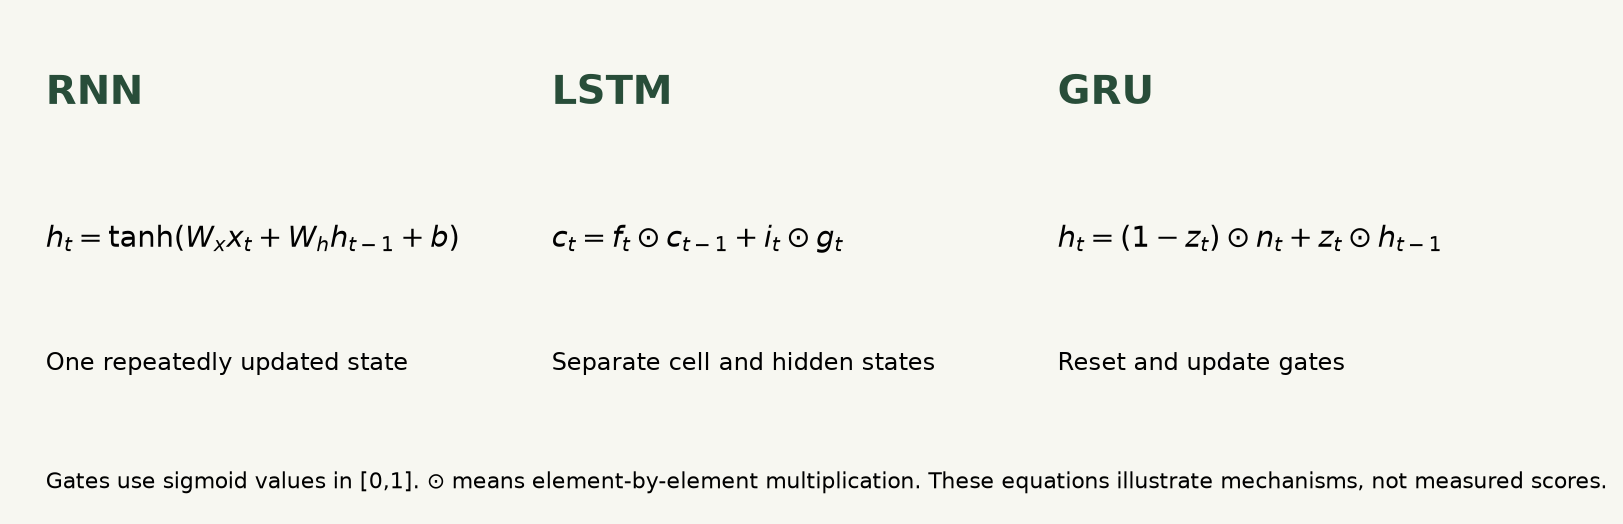

*The GRU equation uses PyTorch’s convention: a large update gate preserves more of the old hidden state.*

## 2. LSTM: separate storage from exposure

An **LSTM**, or long short-term memory network, carries a cell state $c_t$ and a hidden state $h_t$:

$$f_t=\sigma(a_f),\quad i_t=\sigma(a_i),\quad g_t=\tanh(a_g),\quad o_t=\sigma(a_o)$$
$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\qquad h_t=o_t\odot\tanh(c_t).$$

Each preactivation a is a learned linear combination of input and previous hidden state. The **forget gate** scales old cell contents. The **input gate** scales candidate contents. The **output gate** controls what the hidden state exposes. The symbol ⊙ means multiply matching vector components.

The additive cell-state path can support learning longer dependencies. It does not guarantee perfect memory or eliminate every optimization problem. PyTorch packs its four gate projections in the order input, forget, candidate, output. We verify that convention numerically instead of relying on a diagram.

In [3]:
seed_everything()
cell = nn.LSTMCell(input_size=3, hidden_size=4)
x, h_old, c_old = torch.randn(1, 3), torch.randn(1, 4), torch.randn(1, 4)
gates = x @ cell.weight_ih.T + cell.bias_ih + h_old @ cell.weight_hh.T + cell.bias_hh
i_raw, f_raw, g_raw, o_raw = gates.chunk(4, dim=-1)
i, f, g, o = i_raw.sigmoid(), f_raw.sigmoid(), g_raw.tanh(), o_raw.sigmoid()
c_new = f * c_old + i * g
h_new = o * c_new.tanh()
h_library, c_library = cell(x, (h_old, c_old))
assert torch.allclose(h_new, h_library, atol=1e-6)
assert torch.allclose(c_new, c_library, atol=1e-6)
display(pd.DataFrame({"forget": f.detach().numpy()[0], "input": i.detach().numpy()[0],
                     "output": o.detach().numpy()[0], "new cell": c_new.detach().numpy()[0]}))

,forget,input,output,new cell
0,0.342718,0.771606,0.497331,0.062627
1,0.577521,0.241033,0.283287,-0.620418
2,0.573999,0.448571,0.697694,-0.702288
3,0.335186,0.611377,0.402096,-0.543801


## 3. GRU: two gates and one main state

A **gated recurrent unit** uses reset r and update z gates. In PyTorch’s convention:

$$r=\sigma(W_{ir}x+b_{ir}+W_{hr}h+b_{hr}),\quad z=\sigma(W_{iz}x+b_{iz}+W_{hz}h+b_{hz})$$
$$n=\tanh(W_{in}x+b_{in}+r\odot(W_{hn}h+b_{hn}))$$
$$h_{new}=(1-z)\odot n+z\odot h.$$

The reset gate controls how old state contributes to the candidate. A large update gate preserves more old state in this formulation. Some texts define z with the opposite convention, so always read the equation. PyTorch applies its reset gate after the hidden-state projection for the candidate; moving it before the matrix multiplication changes the model.

In [4]:
cell = nn.GRUCell(input_size=3, hidden_size=4)
x, old = torch.randn(1, 3), torch.randn(1, 4)
input_parts = (x @ cell.weight_ih.T + cell.bias_ih).chunk(3, -1)
hidden_parts = (old @ cell.weight_hh.T + cell.bias_hh).chunk(3, -1)
reset = (input_parts[0] + hidden_parts[0]).sigmoid()
update = (input_parts[1] + hidden_parts[1]).sigmoid()
candidate = (input_parts[2] + reset * hidden_parts[2]).tanh()
manual = (1 - update) * candidate + update * old
assert torch.allclose(manual, cell(x, old), atol=1e-6)
print("GRU manual/library maximum difference:", float((manual-cell(x, old)).abs().max().detach()))

GRU manual/library maximum difference: 5.960464477539063e-08


## 4. Put gates into the complete text classifier

The embedding layer and topic head remain unchanged. We replace the recurrent mechanism and still extract the last valid hidden state. An LSTM returns both hidden and cell states; the head reads the hidden state. Packed input prevents trailing padding from altering that final state.

The same hidden width does not mean equal parameter count: gate projections add parameters. This comparison changes architecture and capacity together. All scratch models still start from random embeddings and train only on the course passages.

In [5]:
class RecurrentClassifier(nn.Module):
    """Learn word embeddings, read a sequence and classify its final state.

    Args:
        vocabulary_size: Number of train-fitted word IDs, including PAD/UNK.
        kind: RNN, LSTM or GRU; the rest of the pipeline stays identical.
        width: Embedding and hidden-state dimensions in this classroom model.

    Packing removes padding steps. Without it, a 'final state' could describe
    several padding tokens rather than the end of the learner's sentence.
    """
    def __init__(self, vocabulary_size: int, kind: str = "RNN", width: int = 64):
        super().__init__()
        if kind not in {"RNN", "LSTM", "GRU"}:
            raise ValueError("Choose RNN, LSTM or GRU")
        self.kind = kind
        self.embedding = nn.Embedding(vocabulary_size, width, padding_idx=0)
        self.recurrent = getattr(nn, kind)(width, width, batch_first=True)
        self.dropout = nn.Dropout(0.15)
        self.head = nn.Linear(width, len(LABELS))

    def forward(self, ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        embedded = self.embedding(ids)  # (B,T) -> (B,T,D)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, state = self.recurrent(packed)
        # LSTM returns (hidden state, cell state); classification uses hidden.
        hidden = state[0] if self.kind == "LSTM" else state
        return self.head(self.dropout(hidden[-1]))  # (B,D) -> (B,C)

In [6]:
models = {}
for kind in ["RNN", "LSTM", "GRU"]:
    model = RecurrentClassifier(len(vocabulary), kind)
    model.load_state_dict(torch.load(ROOT / f"artifacts/{kind.lower()}.pt", map_location="cpu", weights_only=True))
    models[kind] = model.eval()
display(pd.DataFrame([{"model": kind, "parameters": sum(p.numel() for p in model.parameters())}
                      for kind, model in models.items()]))

,model,parameters
0,RNN,385926
1,LSTM,410886
2,GRU,402566


## 5. Reproduce a gated run or inspect the saved evidence

The training loop is explained fully in Notebook 1 and available in `coursenav/training.py`. We reuse it so the split, metrics and checkpoint policy remain consistent. Set the flag to train a GRU; its output goes into `artifacts/classroom`, leaving the reference run intact.

In [7]:
if RUN_TRAINING:
    seed_everything()
    experiment, history, seconds = fit(RecurrentClassifier(len(vocabulary), "GRU"),
        TextDataset(train, vocabulary), TextDataset(validation, vocabulary), TrainConfig())
    output = ROOT / "artifacts/classroom"; output.mkdir(exist_ok=True)
    torch.save(experiment.state_dict(), output / "gru.pt")
comparison = [{"model": row["name"], "parameters": row["parameters"],
    "best validation F1": max(epoch["validation_macro_f1"] for epoch in row["history"]),
    "test macro-F1": row["test"]["macro_f1"], "question accuracy": row["questions"]["accuracy"]}
    for row in results if row["name"] in ["rnn", "lstm", "gru"]]
display(pd.DataFrame(comparison).set_index("model"))

,parameters,best validation F1,test macro-F1,question accuracy
model,,,,
rnn,385926,0.283253,0.285193,0.222222
lstm,410886,0.491160,0.477304,0.305556
gru,402566,0.583226,0.481726,0.388889


## 6. Look at disagreements, not just averages

The saved LSTM and GRU passage test macro-F1 scores are about **0.477 and 0.482**. A difference that small in one run is not strong evidence that the GRU is inherently better. Seed variation, uncertainty intervals and repeated data protocols would be needed for a stronger claim.

The question below is an exploratory input, not a new accuracy measurement. A model can predict a plausible topic with high confidence while still missing the learner’s intended meaning. Examine every score and follow the source material.

In [8]:
question = "How can a network keep information from earlier words?"
ids, length = encode(question, vocabulary)
rows = []
with torch.inference_mode():
    for name, model in models.items():
        p = model(torch.tensor([ids]), torch.tensor([length])).softmax(-1)[0]
        rows.append({"model": name, "prediction": LABELS[int(p.argmax())], "raw confidence": float(p.max())})
display(pd.DataFrame(rows))

,model,prediction,raw confidence
0,RNN,Training & evaluation,0.654893
1,LSTM,Transformers & attention,0.494865
2,GRU,Representations & sequences,0.775998


## 7. What gates improve, and what remains

Gates create learnable routes for preserving information; they do not make the model read all tokens simultaneously. These recurrent models still process time steps sequentially. Our final-state head also compresses the entire input into one vector.

Attention offers another mechanism: each token can gather information directly from other allowed tokens. That changes the information path, while introducing quadratic attention-score cost in sequence length. Notebook 3 builds that mechanism explicitly.

**Try it.** Force an LSTM forget gate near zero or one in the manual example. Predict what happens to the old cell’s contribution. Then test how a GRU update gate near one affects its old state.

<details><summary>Worked answer</summary>

Forget near zero suppresses the previous cell term; near one preserves it before adding new candidate content. For the PyTorch GRU convention used here, update near one retains the previous hidden state. Gates control pathways component by component, not whole sentences with a single Boolean switch.

</details>

**Next:** [Notebook 3 — Our small Transformer](03_transformer.ipynb).